<a href="https://colab.research.google.com/github/victoricoma/am-turma5/blob/main/ExercicioCensus_Aula1103.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline|Conector de Drive e Pre-Load de Dados [Census]

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pickle
with open('/content/drive/MyDrive/am-t5/census.pkl', 'rb') as f:
  X_census_train, y_census_train, X_census_test, y_census_test = pickle.load(f)

Provedor de Testes [25%]

In [4]:
X_census_test.shape, y_census_test.shape

((4885, 114), (4885,))

Provedor de Treino [75%]

In [6]:
X_census_train.shape, y_census_train.shape

((27676, 114), (27676,))

# Pipeline | Redes Neurais [Credit Data]

In [7]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [8]:
parametros = {'activation':['relu','logistic','tanh'],
              'solver':['adam','sgd'],
              'batch_size':[10,56]}

In [ ]:
grid_search = GridSearchCV(estimator=MLPClassifier(),param_grid=parametros)
grid_search.fit(X_census_train,y_census_train)
melhores_parametros= grid_search.best_params_
melhor_resultado = grid_search.best_score_

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import DecisionBoundaryDisplay

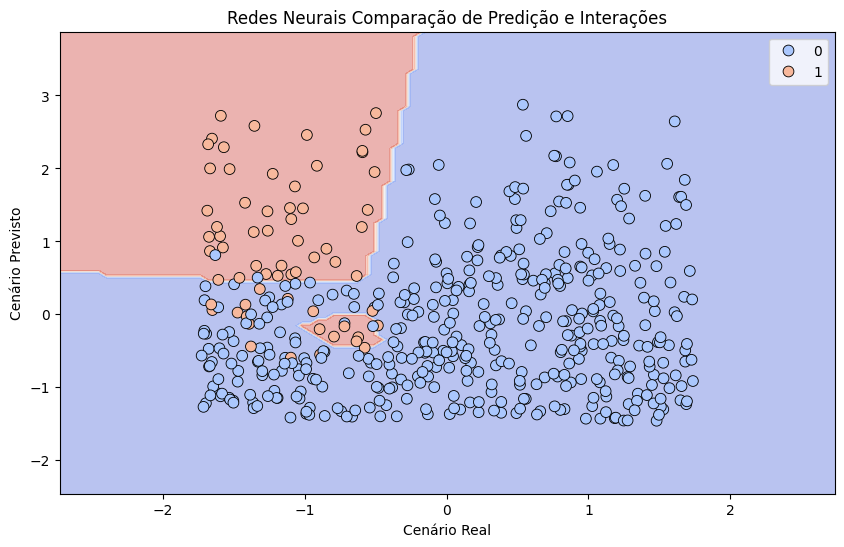

In [ ]:
x_2d = X_credit_test[:, 1:3] # Cenário real da construção do treinamento
y_2d = y_credit_test # Respostas ao cenário real.

rna_2d = MLPClassifier(**grid_search.best_params_, max_iter=1000, random_state=42)
rna_2d.fit(x_2d, y_credit_test) # Cenário sintético da rede Neural

fig, ax = plt.subplots(figsize=(10, 6)) #Montagem dos dois cenários

DecisionBoundaryDisplay.from_estimator(
    rna_2d,
    x_2d,
    cmap="coolwarm",
    alpha=0.4,
    ax=ax,
    response_method="predict"
)

sns.scatterplot(
    x=x_2d[:, 0],
    y=x_2d[:, 1],
    hue=y_credit_test,
    palette="coolwarm",
    edgecolor="black",
    s=60,
    ax=ax
)
plt.title("Redes Neurais Comparação de Predição e Interações")
plt.xlabel("Cenário Real")
plt.ylabel("Cenário Previsto")
plt.show()